# Project 9: Optimizer Comparison Using a Neural Network

**Goal:** Build a simple neural network on the Iris dataset, train it with two optimizers (**SGD** and **Adam**), and compare their training behavior and classification performance.

| Task | Where |
|---|---|
| Task 1: Build a simple neural network on Iris | Sections 1-3 |
| Task 2: Train with SGD and Adam | Sections 4-5 |
| Task 3: Compare training results and classification performance | Sections 6-11 |

## 1. Import Libraries and Load the Iris Dataset

In [14]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import SGD, Adam

SEED = 42

def set_seed(seed=SEED):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed()

iris = load_iris()
X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("Class names:", iris.target_names)

Dataset shape: (150, 4)
Number of classes: 3
Class names: ['setosa' 'versicolor' 'virginica']


## 2. Split and Standardize the Data
The scaler is fit on the training set only, so no information from the test set leaks into training.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 120
Testing samples: 30
Number of features: 4


## 3. Build the Neural Network
Architecture: 4 inputs → Dense(16, ReLU) → Dense(8, ReLU) → Dense(3, softmax). The same architecture, epochs, batch size and validation split are used for both optimizers, so the optimizer is the main thing that changes.

In [16]:
EPOCHS = 150
BATCH_SIZE = 16

def build_model(optimizer):
    model = Sequential([
        Input(shape=(4,)),
        Dense(16, activation='relu'),
        Dense(8, activation='relu'),
        Dense(3, activation='softmax')
    ])
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

build_model(SGD(learning_rate=0.01)).summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_39 (Dense)                │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

## 4. Train the Neural Network Using SGD
SGD with learning rate 0.01 (Keras default).

In [17]:
set_seed()
sgd_model = build_model(SGD(learning_rate=0.01))

sgd_history = sgd_model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    verbose=0
)

print(f"SGD  final epoch -> train loss {sgd_history.history['loss'][-1]:.4f}, "
      f"train acc {sgd_history.history['accuracy'][-1]:.4f}, "
      f"val loss {sgd_history.history['val_loss'][-1]:.4f}, "
      f"val acc {sgd_history.history['val_accuracy'][-1]:.4f}")

SGD  final epoch -> train loss 0.2280, train acc 0.9062, val loss 0.2463, val acc 0.9167


## 5. Train the Neural Network Using Adam
Adam with learning rate 0.001 (Keras default). Each optimizer uses its own standard default learning rate; this is noted again in the conclusion.

In [18]:
set_seed()
adam_model = build_model(Adam(learning_rate=0.001))

adam_history = adam_model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    verbose=0
)

print(f"Adam final epoch -> train loss {adam_history.history['loss'][-1]:.4f}, "
      f"train acc {adam_history.history['accuracy'][-1]:.4f}, "
      f"val loss {adam_history.history['val_loss'][-1]:.4f}, "
      f"val acc {adam_history.history['val_accuracy'][-1]:.4f}")

Adam final epoch -> train loss 0.0864, train acc 0.9688, val loss 0.0460, val acc 1.0000


## 6. Evaluate SGD vs Adam on the Test Set

In [19]:
sgd_loss, sgd_accuracy = sgd_model.evaluate(X_test, y_test, verbose=0)
adam_loss, adam_accuracy = adam_model.evaluate(X_test, y_test, verbose=0)

print("SGD Results")
print("Test Loss:", round(sgd_loss, 4))
print("Test Accuracy:", round(sgd_accuracy * 100, 2), "%")

print("\nAdam Results")
print("Test Loss:", round(adam_loss, 4))
print("Test Accuracy:", round(adam_accuracy * 100, 2), "%")

SGD Results
Test Loss: 0.2899
Test Accuracy: 86.67 %

Adam Results
Test Loss: 0.1074
Test Accuracy: 96.67 %


## 7. Classification Reports and Confusion Matrices

SGD CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.60      0.75        10
   virginica       0.71      1.00      0.83        10

    accuracy                           0.87        30
   macro avg       0.90      0.87      0.86        30
weighted avg       0.90      0.87      0.86        30

ADAM CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



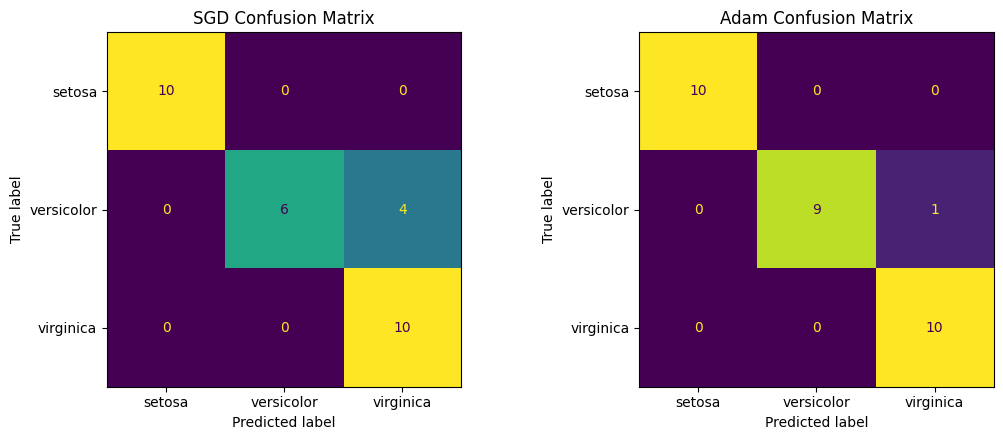

In [20]:
sgd_predictions = np.argmax(sgd_model.predict(X_test, verbose=0), axis=1)
adam_predictions = np.argmax(adam_model.predict(X_test, verbose=0), axis=1)

for name, preds in [("SGD", sgd_predictions), ("ADAM", adam_predictions)]:
    print("=" * 55)
    print(f"{name} CLASSIFICATION REPORT")
    print("=" * 55)
    print(classification_report(y_test, preds, target_names=iris.target_names))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name, preds in zip(axes, ["SGD", "Adam"], [sgd_predictions, adam_predictions]):
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name} Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Compare Training and Validation Loss

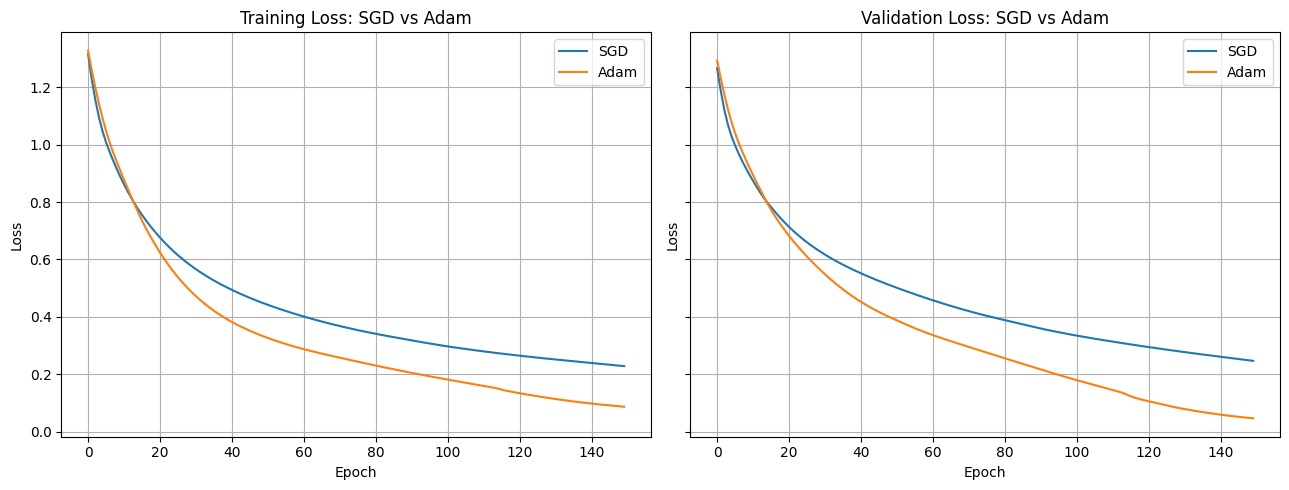

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

axes[0].plot(sgd_history.history['loss'], label='SGD')
axes[0].plot(adam_history.history['loss'], label='Adam')
axes[0].set_title('Training Loss: SGD vs Adam')

axes[1].plot(sgd_history.history['val_loss'], label='SGD')
axes[1].plot(adam_history.history['val_loss'], label='Adam')
axes[1].set_title('Validation Loss: SGD vs Adam')

for ax in axes:
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

## 9. Compare Training and Validation Accuracy

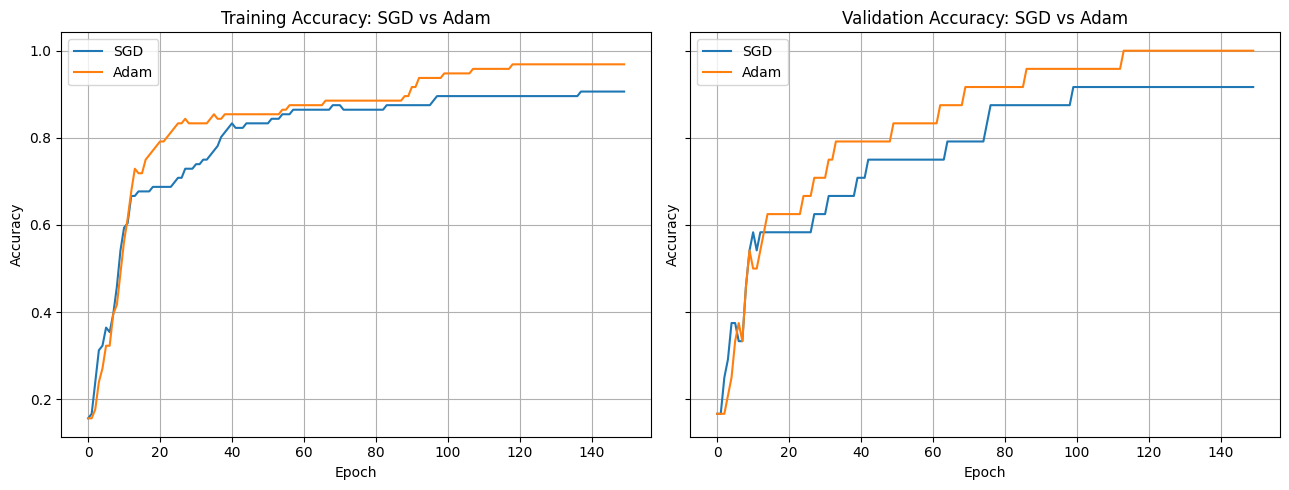

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

axes[0].plot(sgd_history.history['accuracy'], label='SGD')
axes[0].plot(adam_history.history['accuracy'], label='Adam')
axes[0].set_title('Training Accuracy: SGD vs Adam')

axes[1].plot(sgd_history.history['val_accuracy'], label='SGD')
axes[1].plot(adam_history.history['val_accuracy'], label='Adam')
axes[1].set_title('Validation Accuracy: SGD vs Adam')

for ax in axes:
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

## 10. Training Speed: Epochs Needed to Reach a Target

A simple way to quantify "training behavior": how many epochs does each optimizer need before it first reaches a given training loss?

In [23]:
def first_epoch_below(history, threshold):
    losses = np.array(history.history['loss'])
    idx = np.where(losses < threshold)[0]
    return str(int(idx[0]) + 1) if len(idx) else 'not reached'

speed = pd.DataFrame({
    'Training loss below': [0.9, 0.5, 0.2],
    'SGD (epoch)':  [first_epoch_below(sgd_history, t)  for t in [0.9, 0.5, 0.2]],
    'Adam (epoch)': [first_epoch_below(adam_history, t) for t in [0.9, 0.5, 0.2]],
})
print(speed.to_string(index=False))
print("\n(Epoch at which training loss first drops below the threshold; max =", EPOCHS, "epochs)")

 Training loss below SGD (epoch) Adam (epoch)
                 0.9          10           11
                 0.5          40           29
                 0.2 not reached           93

(Epoch at which training loss first drops below the threshold; max = 150 epochs)


## 11. Final Comparison and Robustness Check

A single run on a 30-sample test set is noisy (one sample is worth 3.33%). To check that the result is not just a lucky seed, each optimizer is trained 5 more times with different seeds, using the same split.

In [11]:
comparison = pd.DataFrame({
    'Optimizer': ['SGD', 'Adam'],
    'Learning Rate': [0.01, 0.001],
    'Test Loss': [sgd_loss, adam_loss],
    'Test Accuracy (%)': [sgd_accuracy * 100, adam_accuracy * 100]
})
comparison['Test Loss'] = comparison['Test Loss'].round(4)
comparison['Test Accuracy (%)'] = comparison['Test Accuracy (%)'].round(2)
print("Main run (seed 42):")
print(comparison.to_string(index=False))

def run_once(opt_name, seed):
    set_seed(seed)
    opt = SGD(learning_rate=0.01) if opt_name == 'SGD' else Adam(learning_rate=0.001)
    m = build_model(opt)
    m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
          validation_split=0.2, verbose=0)
    return m.evaluate(X_test, y_test, verbose=0)[1] * 100

seeds = [0, 1, 2, 3, 4]
rows = []
for name in ['SGD', 'Adam']:
    accs = [run_once(name, s) for s in seeds]
    rows.append({'Optimizer': name,
                 'Mean Test Acc (%)': round(np.mean(accs), 2),
                 'Std (%)': round(np.std(accs), 2),
                 'Min (%)': round(min(accs), 2),
                 'Max (%)': round(max(accs), 2)})
robust = pd.DataFrame(rows)
print("\nRobustness check (5 seeds):")
print(robust.to_string(index=False))

Main run (seed 42):
Optimizer  Learning Rate  Test Loss  Test Accuracy (%)
      SGD          0.010     0.2899              86.67
     Adam          0.001     0.1074              96.67

Robustness check (5 seeds):
Optimizer  Mean Test Acc (%)  Std (%)  Min (%)  Max (%)
      SGD              89.33     3.89    83.33    93.33
     Adam              95.33     1.63    93.33    96.67


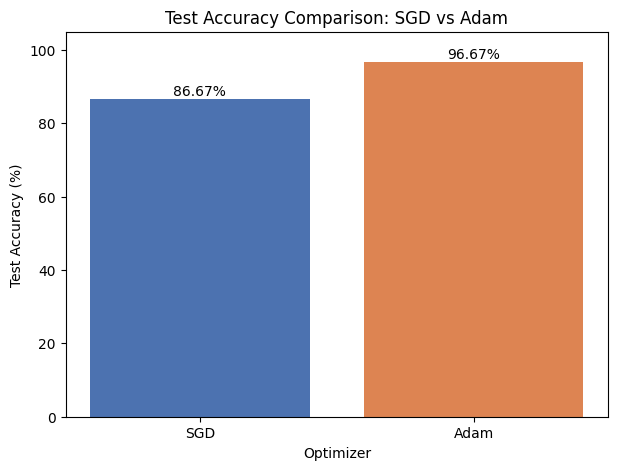

In [12]:
optimizers = ['SGD', 'Adam']
accuracies = [sgd_accuracy * 100, adam_accuracy * 100]

plt.figure(figsize=(7, 5))
bars = plt.bar(optimizers, accuracies, color=['#4C72B0', '#DD8452'])
plt.xlabel('Optimizer')
plt.ylabel('Test Accuracy (%)')
plt.title('Test Accuracy Comparison: SGD vs Adam')
plt.ylim(0, 105)
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
             f'{acc:.2f}%', ha='center')
plt.show()

## Final Result

In [13]:
print("=" * 55)
print("FINAL RESULT")
print("=" * 55)
print(f"SGD  Test Accuracy : {sgd_accuracy * 100:.2f}%   Test Loss : {sgd_loss:.4f}")
print(f"Adam Test Accuracy : {adam_accuracy * 100:.2f}%   Test Loss : {adam_loss:.4f}")

if adam_accuracy > sgd_accuracy:
    print("\nAdam achieved higher test accuracy in this run.")
elif sgd_accuracy > adam_accuracy:
    print("\nSGD achieved higher test accuracy in this run.")
else:
    print("\nBoth optimizers achieved the same test accuracy in this run.")

FINAL RESULT
SGD  Test Accuracy : 86.67%   Test Loss : 0.2899
Adam Test Accuracy : 96.67%   Test Loss : 0.1074

Adam achieved higher test accuracy in this run.


## Conclusion: Differences Between SGD and Adam

**Setup:** same network (4-16-8-3), 150 epochs, batch size 16, 20% validation split, seed 42. SGD used learning rate 0.01 and Adam used 0.001 (each optimizer's usual Keras default), so the comparison reflects each optimizer *with its standard settings*, not a perfectly matched learning rate.

**Training behavior**
- **Early on, both are similar.** Training loss first drops below 0.9 at epoch 10 for SGD and epoch 11 for Adam.
- **Adam pulls ahead later.** It reaches loss 0.5 at epoch 29 (SGD: epoch 40), and it reaches 0.2 at epoch 93, a level SGD never reaches in 150 epochs.
- **Final training loss:** SGD 0.2280 vs Adam 0.0864. Final validation loss: SGD 0.2463 vs Adam 0.0460.
- **Why:** SGD applies the same fixed step size to every weight, so it slows down as gradients get small. Adam keeps per-parameter running averages of the gradient (momentum) and its square (adaptive scaling), which keeps progress going on flat parts of the loss surface.
- **No overfitting seen:** validation loss tracks training loss closely for both optimizers.

**Classification performance (30 test samples)**

| Optimizer | Test accuracy | Test loss | Misclassified |
|---|---|---|---|
| SGD | 86.67% | 0.2899 | 4 |
| Adam | 96.67% | 0.1074 | 1 |

- **Setosa is classified perfectly by both,** because it is linearly separable from the other two classes.
- **All the difference comes from versicolor vs virginica,** which overlap in feature space. SGD's versicolor recall is 0.60 (4 of 10 labeled virginica) while Adam's is 0.90 (1 of 10).

**Robustness:** over 5 additional seeds, Adam averaged 95.33% (std 1.63%) and SGD averaged 89.33% (std 3.89%). Adam was higher on average and also more consistent, so the gap in the main run is not a one-seed fluke. With only 30 test samples, though, each sample is worth 3.33%, so small gaps should not be over-interpreted.

**Takeaway:** with default settings and a fixed epoch budget, Adam converged faster, reached a lower loss, and classified the overlapping classes more accurately. SGD would likely close the gap with more epochs, a higher learning rate or momentum, which is a common reason to still choose it on larger problems.